In [1]:
!pip uninstall -y transformers tokenizers accelerate
!pip cache purge
!pip install -U pip setuptools wheel
!pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "accelerate==0.34.2"

Found existing installation: transformers 5.16.1
Uninstalling transformers-5.16.1:
  Successfully uninstalled transformers-5.16.1
Found existing installation: tokenizers 0.23.1
Uninstalling tokenizers-0.23.1:
  Successfully uninstalled tokenizers-0.23.1
Found existing installation: accelerate 1.14.0
Uninstalling accelerate-1.14.0:
  Successfully uninstalled accelerate-1.14.0
Files removed: 0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 52.8 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the s

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import transformers, tokenizers, accelerate
print("transformers:", transformers.__version__)
print("tokenizers:", tokenizers.__version__)
print("accelerate:", accelerate.__version__)


transformers: 4.46.3
tokenizers: 0.20.3
accelerate: 0.34.2


In [3]:
import pandas as pd
import numpy as np
import random
import torch
import os
import time
import warnings
import json
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer,
    AutoModel,  
    #AutoModelForSequenceClassification, 
    TrainingArguments,
    Trainer,
    #EarlyStoppingCallback
)
import torch.nn as nn #aded for E5 and ...
from google.colab import files
from collections import Counter
import sys
import shutil

warnings.filterwarnings('ignore')

In [23]:
from transformers import set_seed as hf_set_seed 

SEED = 123        #42 & 123 & 2026
NUM_LABELS = 5

def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    hf_set_seed(seed)  

set_seed(SEED)
print(f" {SEED}")
print(f" Python: {sys.version.split()[0]}")
print(f" PyTorch: {torch.__version__}")
print(f" CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f" GPU: {torch.cuda.get_device_name(0)}")

 123
 Python: 3.13.15
 PyTorch: 2.11.0+cu128
 CUDA Available: True
 GPU: Tesla T4


In [24]:
print("Upload Train Dataset")
uploaded_train = files.upload()
train_file = list(uploaded_train.keys())[0]

Upload Train Dataset


Saving translationDSCG.csv to translationDSCG.csv


In [7]:
print("Upload Test Dataset")
uploaded_test = files.upload()
test_file = list(uploaded_test.keys())[0]

Upload Test Dataset


Saving test.csv to test.csv


In [25]:
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

if len(train_df.columns) == 2:
    train_df.columns = ['text', 'label']
if len(test_df.columns) == 2:
    test_df.columns = ['text', 'label']

print(f"- Train Data: {len(train_df)} ")
print(f"- Test Data: {len(test_df)} ")

- Train Data: 15691 
- Test Data: 1853 


In [26]:
def clean_data(df):
    df = df.copy()
    df['text'] = df['text'].astype(str).str.strip()
    df = df[df['text'].str.len() > 3]
    return df
train_df = clean_data(train_df)
test_df = clean_data(test_df)

print(f"- Train Data: {len(train_df)} ")
print(f"- Test Data: {len(test_df)} ")

- Train Data: 15691 
- Test Data: 1853 


In [27]:
# Lable Mapping
label_mapping = {-2: 0, -1: 1, 0: 2, 1: 3, 2: 4}
for orig, new in label_mapping.items():
    print(f"  {orig} --> {new}")

  -2 --> 0
  -1 --> 1
  0 --> 2
  1 --> 3
  2 --> 4


In [28]:
train_df['label'] = train_df['label'].map(label_mapping)
test_df['label'] = test_df['label'].map(label_mapping)

train_df = train_df.dropna(subset=['label'])
test_df = test_df.dropna(subset=['label'])

train_df['label'] = train_df['label'].astype(int)
test_df['label'] = test_df['label'].astype(int)

X_train_full = train_df['text'].tolist()
y_train_full = train_df['label'].tolist()
X_test = test_df['text'].tolist()
y_test = test_df['label'].tolist()

In [29]:
print("Class Distribution:")
train_dist = Counter(y_train_full)
test_dist = Counter(y_test)

print("Train Data:")
for label, count in sorted(train_dist.items()):
    print(f"  Class {label}: {count} ({count/len(y_train_full)*100:.1f}%)")

print("\n Test Data:")
for label, count in sorted(test_dist.items()):
    print(f"  Class {label}: {count}  ({count/len(y_test)*100:.1f}%)")

Class Distribution:
Train Data:
  Class 0: 324 (2.1%)
  Class 1: 2026 (12.9%)
  Class 2: 4713 (30.0%)
  Class 3: 4480 (28.6%)
  Class 4: 4148 (26.4%)

 Test Data:
  Class 0: 12  (0.6%)
  Class 1: 184  (9.9%)
  Class 2: 743  (40.1%)
  Class 3: 560  (30.2%)
  Class 4: 354  (19.1%)


In [30]:
# *************** Data Split to Train/Validation ************************
print(f"\n Data Split to Train/Validation (seed={SEED})")
print("*Note*: Test set is already separate (uploaded file)!!!")

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,  # 15%
    random_state=SEED,
    stratify=y_train_full
)

print(f"Final Split:")
print(f"• Train: {len(X_train)} ({len(X_train)/len(X_train_full)*100:.1f}%)")
print(f"• Validation: {len(X_val)} ({len(X_val)/len(X_train_full)*100:.1f}%)")
print(f"• Test: {len(X_test)}")


 Data Split to Train/Validation (seed=123)
*Note*: Test set is already separate (uploaded file)!!!
Final Split:
• Train: 13337 (85.0%)
• Validation: 2354 (15.0%)
• Test: 1853


In [31]:
class EmbeddingClassifier(nn.Module):
    def __init__(self, model_name, num_labels):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.classifier = nn.Linear(
            self.encoder.config.hidden_size, num_labels
        )

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True
        )

        # Mean Pooling (For embedding models)
        pooled_output = outputs.last_hidden_state.mean(dim=1)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
            loss = nn.CrossEntropyLoss()(logits, labels)

        return {
            "loss": loss,
            "logits": logits
        }

In [32]:
# ****************** Model and Tokenizer ***************

# ##### Model Selection (Uncomment a Model) ########


#MODEL_NAME = "agentlans/multilingual-e5-small-aligned-sentiment"     # E5_Small
#MODEL_NAME = "Ludo33/e5_Sentiment_General_v2"                        # E5_General
MODEL_NAME = "Alibaba-NLP/gte-multilingual-base"                     #GTE
#MODEL_NAME = "Alibaba-NLP/gte-multilingual-reranker-base"             #GTE_Reranker



print(f"\n Selected Model: {MODEL_NAME}")

try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    print(f"Done!")
except Exception as e:
    print(f"ERROR!!!: {e}")
    tokenizer = AutoTokenizer.from_pretrained("Ludo33/e5_Sentiment_General_v2")
###  For E5 and ....
def tokenize_function(texts):
    texts = ["query: " + t for t in texts]
    return tokenizer(
        texts,
        truncation=True,
        padding=True,
        max_length=128,
        return_tensors="pt"
    )

train_encodings = tokenize_function(X_train)
val_encodings = tokenize_function(X_val)
test_encodings = tokenize_function(X_test)


 Selected Model: Alibaba-NLP/gte-multilingual-base
Done!


In [33]:
class PersianSentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = PersianSentimentDataset(train_encodings, y_train)
val_dataset = PersianSentimentDataset(val_encodings, y_val)
test_dataset = PersianSentimentDataset(test_encodings, y_test)

In [34]:
# *********************** Metrics ********************
def compute_metrics(p):
    predictions = p.predictions.argmax(-1)
    labels = p.label_ids

    accuracy = accuracy_score(labels, predictions)
    f1_weighted = f1_score(labels, predictions, average='weighted')
    f1_macro = f1_score(labels, predictions, average='macro')

    return {
        'accuracy': accuracy,
        'f1_weighted': f1_weighted,
        'f1_macro': f1_macro,
    }

In [35]:
# ********************  Hyperparameters  ********************

HYPERPARAM_COMBINATIONS = [
    #{'lr': 2e-5, 'batch_size': 8, 'epochs': 3},
    #{'lr': 3e-5, 'batch_size': 16, 'epochs': 3},
    {'lr': 5e-5, 'batch_size': 16, 'epochs': 3},
    #{'lr': 2e-5, 'batch_size': 32, 'epochs': 3},
    #{'lr': 5e-5, 'batch_size': 32, 'epochs': 3},
]

results = []
best_val_accuracy = 0
best_model_checkpoint_path = None
best_hyperparams = None
best_combination_id = None

os.makedirs("./hyperparameter_search", exist_ok=True)

for idx, hp in enumerate(HYPERPARAM_COMBINATIONS, 1):
    print(f"\n{'='*60}")
    print(f" Combination {idx}/{len(HYPERPARAM_COMBINATIONS)}")
    print(f"{'='*60}")
    print(f"   • Learning Rate: {hp['lr']:.0e}")
    print(f"   • Batch Size: {hp['batch_size']}")
    print(f"   • Epochs: {hp['epochs']}")

    start_time = time.time()

    try:
        timestamp = int(time.time())
        combination_output_dir = f"./hyperparameter_search/combination_{idx}_{timestamp}"
        os.makedirs(combination_output_dir, exist_ok=True)

        model = EmbeddingClassifier(
        model_name=MODEL_NAME,
        num_labels=NUM_LABELS
        )


        import transformers
        TRANSFORMERS_VERSION = transformers.__version__
        print(f"   • Transformers version: {TRANSFORMERS_VERSION}")

        if hasattr(TrainingArguments, 'evaluation_strategy'):
            eval_strat_param = 'evaluation_strategy'
            save_strat_param = 'save_strategy'
        else:
            eval_strat_param = 'eval_strategy'
            save_strat_param = 'save_strategy'

        # Training Settings
        training_args_dict = {
            'output_dir': combination_output_dir,
            'num_train_epochs': hp['epochs'],
            'per_device_train_batch_size': hp['batch_size'],
            'per_device_eval_batch_size': hp['batch_size'],
            'learning_rate': hp['lr'],
            #'warmup_ratio': 0.1,
            'weight_decay': 0.01,
            #'logging_dir': f'./logs/combination_{idx}',
            'logging_steps': 50,
            eval_strat_param: "epoch",
            save_strat_param: "epoch",
            'load_best_model_at_end': True,
            'metric_for_best_model': "eval_accuracy",
            'greater_is_better': True,
            'save_total_limit': 1,
            'fp16': torch.cuda.is_available(),
            'report_to': "none",
            'seed': SEED,
            #'data_seed': SEED,  
            'dataloader_drop_last': False,
            'remove_unused_columns': True,
            'label_names': ["labels"]
        }

        training_args = TrainingArguments(**training_args_dict)

        # Trainer
        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_dataset,
            eval_dataset=val_dataset,
            compute_metrics=compute_metrics,
            #callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )

        train_result = trainer.train()

        print("Evaluate on Validation Set...")
        val_metrics = trainer.evaluate(val_dataset)

        training_time = time.time() - start_time

        result = {
            'combination_id': idx,
            'learning_rate': hp['lr'],
            'batch_size': hp['batch_size'],
            'epochs': hp['epochs'],
            'val_accuracy': val_metrics['eval_accuracy'],
            'val_f1_weighted': val_metrics['eval_f1_weighted'],
            'val_f1_macro': val_metrics['eval_f1_macro'],
            'training_loss': train_result.training_loss,
            'training_time_seconds': training_time,
            'training_time_minutes': training_time / 60,
            'model_checkpoint': combination_output_dir,
            'timestamp': timestamp
        }

        results.append(result)

        print(f"\n  Validation Results:")
        print(f"   {'─' * 40}")
        print(f"   • Accuracy: {val_metrics['eval_accuracy']*100:.2f}%")
        print(f"   • F1-Score (Weighted): {val_metrics['eval_f1_weighted']*100:.2f}%")
        print(f"   • F1-Score (Macro): {val_metrics['eval_f1_macro']*100:.2f}%")
        print(f"   • Training Loss: {train_result.training_loss:.4f}")
        print(f"   • Training Time: {training_time/60:.1f} min")
        print(f"   • Checkpoint: {combination_output_dir}")

        # Best Model
        if val_metrics['eval_accuracy'] > best_val_accuracy:
            best_val_accuracy = val_metrics['eval_accuracy']
            best_model_checkpoint_path = combination_output_dir
            best_hyperparams = hp.copy()
            best_combination_id = idx

            print(f"\n   !!!NEW BEST MODEL!!!")
            print(f"    Accuracy Improved: {best_val_accuracy*100:.2f}%")
            print(f"    Best model path checkpoint: {best_model_checkpoint_path}")

        del model
        del trainer
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    except Exception as e:
        print(f"\n   ERROR!!! {idx}: {str(e)}")
        import traceback
        traceback.print_exc()

        error_result = {
            'combination_id': idx,
            'learning_rate': hp['lr'],
            'batch_size': hp['batch_size'],
            'epochs': hp['epochs'],
            'error': str(e),
            'val_accuracy': 0.0,
            'training_time_seconds': time.time() - start_time
        }
        results.append(error_result)
        continue


 Combination 1/1
   • Learning Rate: 5e-05
   • Batch Size: 16
   • Epochs: 3
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


   • Transformers version: 4.46.3


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,0.795100,0.734215,0.706457,0.699381,0.622663
2,0.519700,0.706568,0.731521,0.727659,0.677343
3,0.325700,0.803628,0.745540,0.743893,0.700462


Evaluate on Validation Set...



  Validation Results:
   ────────────────────────────────────────
   • Accuracy: 74.55%
   • F1-Score (Weighted): 74.39%
   • F1-Score (Macro): 70.05%
   • Training Loss: 0.5763
   • Training Time: 23.2 min
   • Checkpoint: ./hyperparameter_search/combination_1_1789511871

   !!!NEW BEST MODEL!!!
    Accuracy Improved: 74.55%
    Best model path checkpoint: ./hyperparameter_search/combination_1_1789511871


In [36]:
# ******************** Results Analysis **********************

results_df = pd.DataFrame(results)

valid_results = results_df[results_df['val_accuracy'] > 0]

if len(valid_results) > 0:
    valid_results = valid_results.sort_values('val_accuracy', ascending=False)

    print(f"Best Validation Accuracy: {valid_results.iloc[0]['val_accuracy']*100:.2f}%")

    print("\n" + "="*70)
    print("Ranking of combinations based on Validation")
    print("="*70)

    for i, (_, row) in enumerate(valid_results.iterrows(), 1):
        print(f"\n{i}. Combination #{int(row['combination_id'])}")
        print(f"   • LR={row['learning_rate']:.0e}, BS={int(row['batch_size'])}, Epochs={int(row['epochs'])}")
        print(f"   • Accuracy: {row['val_accuracy']*100:.2f}%")
        print(f"   • F1-Weighted: {row['val_f1_weighted']*100:.2f}%")
        print(f"   • Time: {row['training_time_minutes']:.1f} min")

    # Best Combination
    best_row = valid_results.iloc[0]
    print(f"• Combination ID: #{int(best_row['combination_id'])}")
    print(f"• Learning Rate: {best_row['learning_rate']:.0e}")
    print(f"• Batch Size: {best_row['batch_size']}")
    print(f"• Epochs: {best_row['epochs']}")
    print(f"• Validation Accuracy: {best_row['val_accuracy']*100:.2f}%")
    print(f"• Validation F1-Weighted: {best_row['val_f1_weighted']*100:.2f}%")
    print(f"• Validation F1-Macro: {best_row['val_f1_macro']*100:.2f}%")     
    print(f"• Training Time: {best_row['training_time_minutes']:.1f} min")
    print(f"• Checkpoint Path: {best_model_checkpoint_path}")
else:
    print("ERROR!!!")
    best_model_checkpoint_path = None

Best Validation Accuracy: 74.55%

Ranking of combinations based on Validation

1. Combination #1
   • LR=5e-05, BS=16, Epochs=3
   • Accuracy: 74.55%
   • F1-Weighted: 74.39%
   • Time: 23.2 min
• Combination ID: #1
• Learning Rate: 5e-05
• Batch Size: 16
• Epochs: 3
• Validation Accuracy: 74.55%
• Validation F1-Weighted: 74.39%
• Validation F1-Macro: 70.05%
• Training Time: 23.2 min
• Checkpoint Path: ./hyperparameter_search/combination_1_1789511871


In [37]:
# ****************** Retraining with the Best Parameters ******************

if best_hyperparams and len(valid_results) > 0:
    print(f"Best Parameters:")
    print(f"   • Learning Rate: {best_hyperparams['lr']:.0e}")
    print(f"   • Batch Size: {best_hyperparams['batch_size']}")
    print(f"   • Epochs: {best_hyperparams['epochs']}")

    print("\n Cobination of Train + Validation for the Final Training...")
    X_train_final = X_train + X_val
    y_train_final = y_train + y_val

    train_final_encodings = tokenize_function(X_train_final)
    train_final_dataset = PersianSentimentDataset(train_final_encodings, y_train_final)

    final_model = EmbeddingClassifier(
        model_name=MODEL_NAME,
        num_labels=NUM_LABELS
        )

    import transformers
    if hasattr(TrainingArguments, 'evaluation_strategy'):
        eval_strat_param = 'evaluation_strategy'
    else:
        eval_strat_param = 'eval_strategy'

    # Final Training Settings
    final_args_dict = {
        'output_dir': './final_model_training',
        'num_train_epochs': best_hyperparams['epochs'],
        'per_device_train_batch_size': best_hyperparams['batch_size'],
        'per_device_eval_batch_size': best_hyperparams['batch_size'],
        'learning_rate': best_hyperparams['lr'],
        #'warmup_ratio': 0.1,
        'weight_decay': 0.01,
        #'logging_dir': './logs/final_training',
        'logging_steps': 50,
        eval_strat_param: "no",
        save_strat_param: "no", 
        'save_strategy': "no",
        'fp16': torch.cuda.is_available(),
        'report_to': "none",
        'seed': SEED,
        #'data_seed': SEED,   
        'dataloader_drop_last': False,
        'remove_unused_columns': True,
        'label_names': ["labels"],
        'load_best_model_at_end': False
    }

    final_args = TrainingArguments(**final_args_dict)

    final_trainer = Trainer(
        model=final_model,
        args=final_args,
        train_dataset=train_final_dataset,
        compute_metrics=compute_metrics
    )

    print("Retraining...")
    start_time = time.time()
    final_trainer.train()
    training_time = time.time() - start_time

    print(f"Done! ({training_time/60:.1f} min)")

    final_model_dir = "./final_trained_model"
    final_trainer.save_model(final_model_dir)
    tokenizer.save_pretrained(final_model_dir)

    best_model = final_model
    best_trainer = final_trainer

else:
    print("ERROR!!!")
    best_model = None
    best_trainer = None

Best Parameters:
   • Learning Rate: 5e-05
   • Batch Size: 16
   • Epochs: 3

 Cobination of Train + Validation for the Final Training...
The repository for Alibaba-NLP/gte-multilingual-base contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Alibaba-NLP/gte-multilingual-base.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Some weights of the model checkpoint at Alibaba-NLP/gte-multilingual-base were not used when initializing NewModel: ['classifier.bias', 'classifier.weight']
- This IS expected if you are initializing NewModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing NewModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Retraining...


Step,Training Loss
50,1.242100
100,1.042200
150,0.972100
200,0.900100
250,0.895400
300,0.857500
350,0.862600
400,0.857300
450,0.878300
500,0.830000


Done! (13.0 min)



 Final Results on Test Set:
•  Accuracy: 74.31%
• F1-Score (Weighted): 74.64%
• F1-Score (Macro): 67.61%


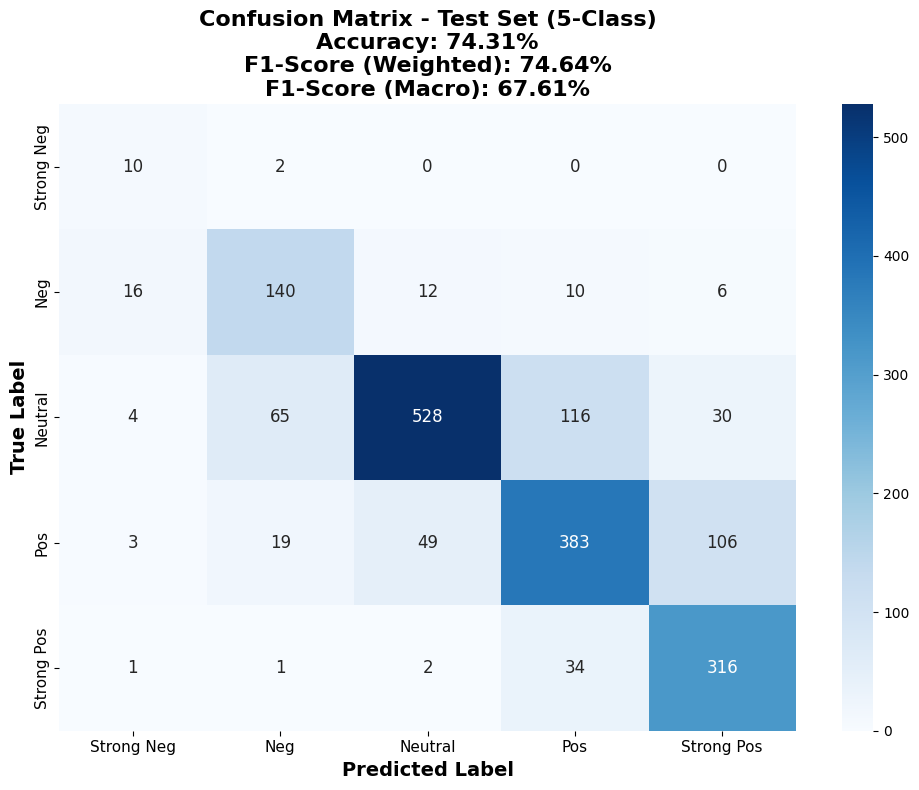


 Confusion Matrix (Text Format):
  Strong Neg (True) → Strong Neg (Pred): 10
  Strong Neg (True) → Neg (Pred): 2
  Strong Neg (True) → Neutral (Pred): 0
  Strong Neg (True) → Pos (Pred): 0
  Strong Neg (True) → Strong Pos (Pred): 0
--------------------------------------------------
  Neg (True) → Strong Neg (Pred): 16
  Neg (True) → Neg (Pred): 140
  Neg (True) → Neutral (Pred): 12
  Neg (True) → Pos (Pred): 10
  Neg (True) → Strong Pos (Pred): 6
--------------------------------------------------
  Neutral (True) → Strong Neg (Pred): 4
  Neutral (True) → Neg (Pred): 65
  Neutral (True) → Neutral (Pred): 528
  Neutral (True) → Pos (Pred): 116
  Neutral (True) → Strong Pos (Pred): 30
--------------------------------------------------
  Pos (True) → Strong Neg (Pred): 3
  Pos (True) → Neg (Pred): 19
  Pos (True) → Neutral (Pred): 49
  Pos (True) → Pos (Pred): 383
  Pos (True) → Strong Pos (Pred): 106
--------------------------------------------------
  Strong Pos (True) → Strong Neg (Pre

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done!


In [38]:
# ************ Final Evaluation on Test Set ****************

if best_trainer is not None:

    try:
        test_predictions = best_trainer.predict(test_dataset)

        test_preds = test_predictions.predictions.argmax(-1)

        test_accuracy = accuracy_score(y_test, test_preds)
        test_f1_weighted = f1_score(y_test, test_preds, average='weighted')
        test_f1_macro = f1_score(y_test, test_preds, average='macro')

        print(f"\n Final Results on Test Set:")
        print(f"•  Accuracy: {test_accuracy*100:.2f}%")
        print(f"• F1-Score (Weighted): {test_f1_weighted*100:.2f}%")
        print(f"• F1-Score (Macro): {test_f1_macro*100:.2f}%")

        cm = confusion_matrix(y_test, test_preds)

        class_labels = ['Strong Neg', 'Neg', 'Neutral', 'Pos', 'Strong Pos']

        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=class_labels,
                    yticklabels=class_labels,
                    annot_kws={'size': 12})
        plt.xlabel('Predicted Label', fontsize=14, fontweight='bold')
        plt.ylabel('True Label', fontsize=14, fontweight='bold')
        plt.title(f'Confusion Matrix - Test Set (5-Class)\nAccuracy: {test_accuracy*100:.2f}%\nF1-Score (Weighted): {test_f1_weighted*100:.2f}%\nF1-Score (Macro): {test_f1_macro*100:.2f}%',
                  fontsize=16, fontweight='bold')
        plt.xticks(fontsize=11)
        plt.yticks(fontsize=11)
        plt.tight_layout()

        plt.savefig('confusion_matrix_5class.png', dpi=300, bbox_inches='tight')
        plt.show()

        print("\n Confusion Matrix (Text Format):")
        print("="*50)
        for i, label in enumerate(class_labels):
            for j, pred_label in enumerate(class_labels):
                print(f"  {label} (True) → {pred_label} (Pred): {cm[i, j]}")
            print("-"*50)


        output_df = pd.DataFrame({
            'true_label': y_test,
            'predicted_label': test_preds
        })
        output_df.to_csv('model_predictions.csv', index=False, encoding='utf-8-sig')
        files.download('model_predictions.csv')
        print("Done!")


    except Exception as e:
        print(f"ERROR!!!: {str(e)}")
        import traceback
        traceback.print_exc()
else:
    print("ERROR!!!")